In [1]:
import uproot
import matplotlib.pyplot as plt
import pandas as pd
import tqdm
import numpy as np
import os
import glob
import awkward as ak
import boost_histogram as bh
import mplhep as mh
from matplotlib.colors import LogNorm
import math
mh.style.use("ATLAS")
import particle
# !pip install pyarrow
# !pip install "pyarrow<21" --break-system-packages

In [3]:
files = glob.glob("build/noTruthCuts/raw/*.root")
files = [f"{f}:nt" for f in files]
events = uproot.concatenate(files, library="ak")

In [4]:
# Filter events with at least two tracks
ditrack_events = events[events['longTracks'] >= 2]
print(f"Number of events with at least 2 tracks: {len(ditrack_events)}")

Number of events with at least 2 tracks: 43101


In [5]:
def get_truth_matched_fraction(ak_record):
    truth_matched_events = []
    not_truth_matched_events = []

    for event in tqdm.tqdm(ak_record):
        # Get index of highest momentum truth matched track and ask if it is a muon from a neutrino interaction
        idx = np.argmax(event["t_pz"])
        truth_matched_pdg = event["t_pdg"][idx]
        truth_matched_parent_pdg = event["t_pdg_parent"][idx]
    
        if abs(truth_matched_pdg) == 13 and abs(truth_matched_parent_pdg) in [12, 14, 16]:
            truth_matched_events.append(event)
        else:
            not_truth_matched_events.append(event)

    return truth_matched_events, not_truth_matched_events, len(truth_matched_events) / len(ak_record), len(not_truth_matched_events) / len(ak_record)

In [6]:
ditrack_events_truth_matched, ditrack_events_not_truth_matched, truth_matched_fraction, not_truth_matched_fraction = get_truth_matched_fraction(ditrack_events)
print(f"Truth matched fraction: {truth_matched_fraction:.2%}")
print(f"Not truth matched fraction: {not_truth_matched_fraction:.2%}")

100%|██████████| 43101/43101 [00:26<00:00, 1603.31it/s]

Truth matched fraction: 73.37%
Not truth matched fraction: 26.63%


In [7]:
def get_particle_names(pdg_list, use_pm=False):
    particle_names = []
    for pdg in pdg_list:
        if pdg == 0:
            particle_names.append("Not matched")
            continue

        try:
            particle_names.append("$" + particle.Particle.from_pdgid(pdg).latex_name + "$")
        except ValueError:
            particle_names.append("Unknown")
    if use_pm:
        particle_names = [name.replace("+", "\\pm").replace("-", "\\pm") for name in particle_names]
    return sorted(particle_names)

In [8]:
# seperate ditrack_events_truth_matched into the different sub-leading truth matched particle types based on the pdg of the sub-leading track
# get the calo energy 

calo_energy_dict = {}
radius_dict = {}
pz_dict = {}
ps_tot_nmip_dict = {}

for event in tqdm.tqdm(ditrack_events_truth_matched):
    # Get the pdg of the sub-leading track
    sub_leading_idx = np.argsort(event["t_pz"])[-2]
    sub_leading_pdg = abs(event["t_pdg"][np.argsort(event["t_pz"])[-2]])
    # Get the calo energy of the event

    calo_tot_variable = "CaloHi_total_E_EM"
    if calo_tot_variable not in event.fields:
        calo_tot_variable = "Calo_total_E_EM"

    Calo_total_E_EM = event[calo_tot_variable] / 1000  # Convert to GeV

    radius_st0 = np.sqrt(event["t_st0_x"][sub_leading_idx]**2 + event["t_st0_y"][sub_leading_idx]**2)
    radius_st1 = np.sqrt(event["t_st1_x"][sub_leading_idx]**2 + event["t_st1_y"][sub_leading_idx]**2)
    radius_st2 = np.sqrt(event["t_st2_x"][sub_leading_idx]**2 + event["t_st2_y"][sub_leading_idx]**2)
    radius_st3 = np.sqrt(event["t_st3_x"][sub_leading_idx]**2 + event["t_st3_y"][sub_leading_idx]**2)
    max_radius = max(radius_st0, radius_st1, radius_st2, radius_st3)

    if sub_leading_pdg not in calo_energy_dict:
        calo_energy_dict[sub_leading_pdg] = []
    calo_energy_dict[sub_leading_pdg].append(Calo_total_E_EM)

    if sub_leading_pdg not in radius_dict:
        radius_dict[sub_leading_pdg] = []
    radius_dict[sub_leading_pdg].append(max_radius)

    if sub_leading_pdg not in pz_dict:
        pz_dict[sub_leading_pdg] = []
    pz_dict[sub_leading_pdg].append(event["t_pz"][sub_leading_idx] / 1000)  # Convert to GeV

    if sub_leading_pdg not in ps_tot_nmip_dict:
        ps_tot_nmip_dict[sub_leading_pdg] = []
    ps_tot_nmip_dict[sub_leading_pdg].append(event["Preshower_total_nMIP"])


100%|██████████| 31623/31623 [01:07<00:00, 469.58it/s]


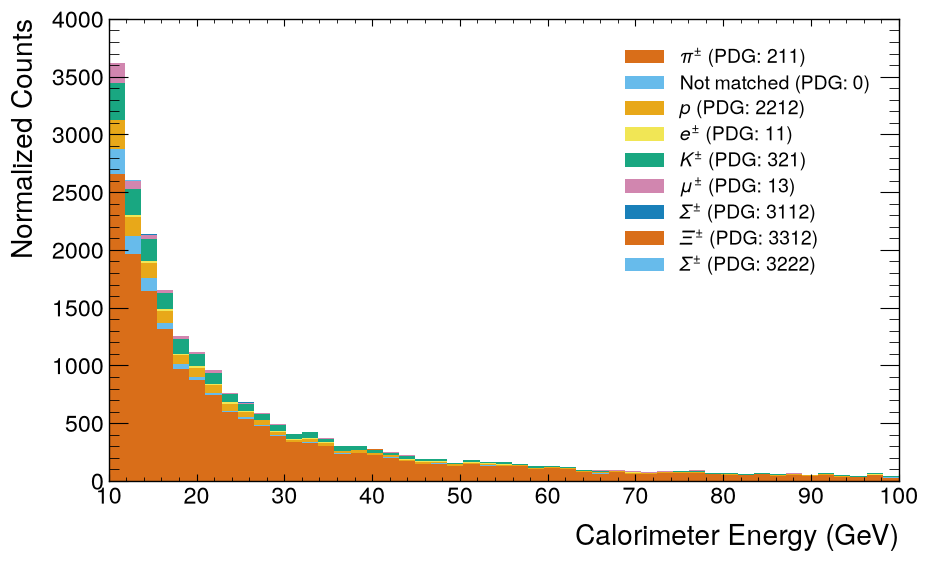

In [9]:
fig, ax = plt.subplots(figsize=(10, 6))
bins = np.linspace(10, 100, 50)  # Define bins for the histogram
bottom = 0
for pdg, calo_energies in calo_energy_dict.items():
    ax.hist(calo_energies, bins=bins, alpha=0.9, label=f"{get_particle_names([pdg], use_pm=True)[0]} (PDG: {pdg})", density=False, histtype='stepfilled', bottom=bottom)
    bottom += np.histogram(calo_energies, bins=bins)[0]
ax.set_xlabel("Calorimeter Energy (GeV)")
ax.set_ylabel("Normalized Counts")
ax.legend()
    


/home/ppd/bewilson/miniconda3/envs/faser/lib/python3.12/site-packages/matplotlib/axes/_axes.py:7487: RuntimeWarning: All-NaN slice encountered
  xmin = min(xmin, np.nanmin(xi))
/home/ppd/bewilson/miniconda3/envs/faser/lib/python3.12/site-packages/matplotlib/axes/_axes.py:7488: RuntimeWarning: All-NaN slice encountered
  xmax = max(xmax, np.nanmax(xi))


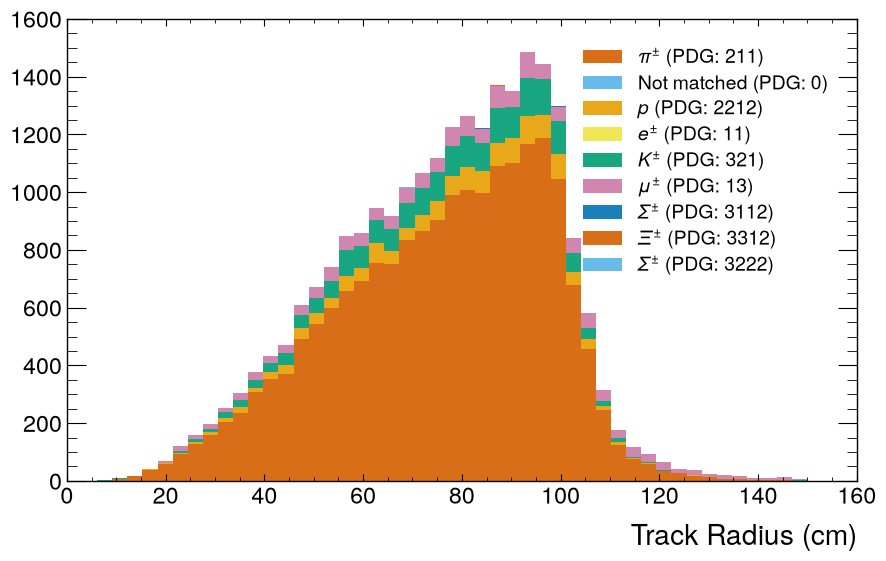

In [10]:
fig, ax = plt.subplots(figsize=(10, 6))
bins = np.linspace(0, 150, 50)  # Define bins for the histogram
bottom = 0
for pdg, track_radii in radius_dict.items():
    ax.hist(track_radii, bins=bins, alpha=0.9, label=f"{get_particle_names([pdg], use_pm=True)[0]} (PDG: {pdg})", density=False, histtype='stepfilled', bottom=bottom)
    bottom += np.histogram(track_radii, bins=bins)[0]
ax.set_xlabel("Track Radius (cm)")
ax.legend()
    


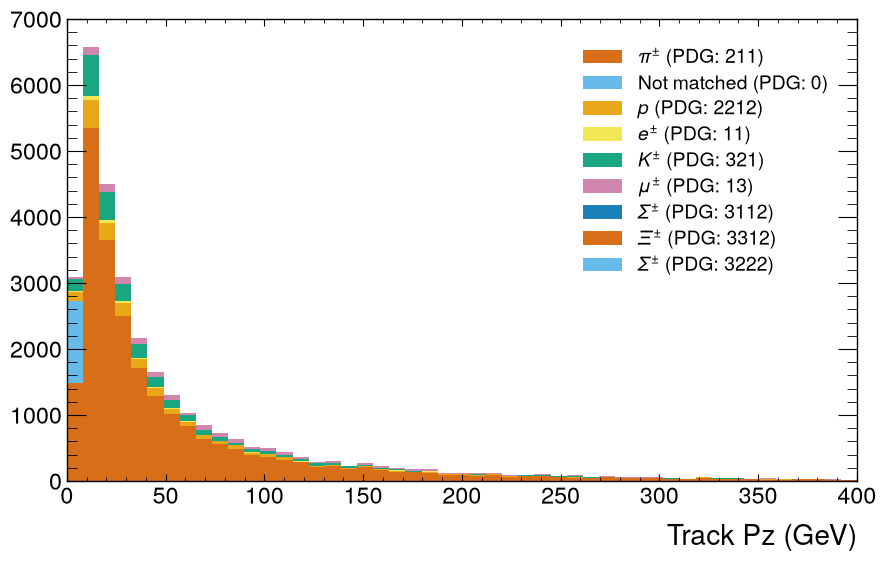

In [11]:
fig, ax = plt.subplots(figsize=(10, 6))
bins = np.linspace(0, 400, 50)  # Define bins for the histogram
bottom = 0
for pdg, track_pz in pz_dict.items():
    ax.hist(track_pz, bins=bins, alpha=0.9, label=f"{get_particle_names([pdg], use_pm=True)[0]} (PDG: {pdg})", density=False, histtype='stepfilled', bottom=bottom)
    bottom += np.histogram(track_pz, bins=bins)[0]
ax.set_xlabel("Track Pz (GeV)")
ax.legend()
    


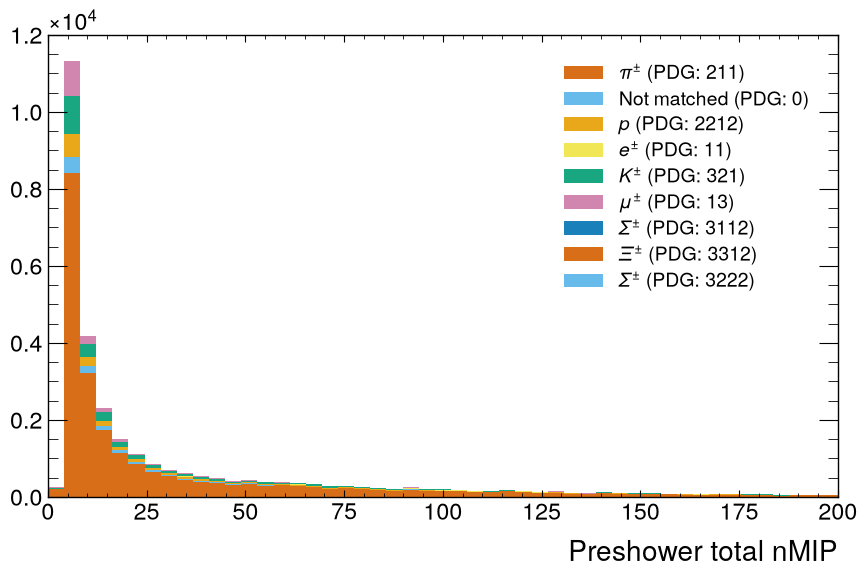

In [12]:
fig, ax = plt.subplots(figsize=(10, 6))
bins = np.linspace(0, 200, 50)  # Define bins for the histogram
bottom = 0
for pdg, ps_nmip in ps_tot_nmip_dict.items():
    ax.hist(ps_nmip, bins=bins, alpha=0.9, label=f"{get_particle_names([pdg], use_pm=True)[0]} (PDG: {pdg})", density=False, histtype='stepfilled', bottom=bottom)
    bottom += np.histogram(ps_nmip, bins=bins)[0]
ax.set_xlabel("Preshower total nMIP")
ax.legend()
    


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 57.6/57.6 MB 37.5 MB/s  0:00:01m0:00:0100:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 305.1/305.1 MB 88.3 MB/s  0:00:03m0:00:0100:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2/2 [xgboost]m1/2 [xgboost]
